In [2]:
import pandas as pd
import os

file_path = r"C:\Users\lenovo\OneDrive\Desktop\data science\WINE-NAIVE-BAYES\wine.csv"

print(os.path.exists(file_path))

df = pd.read_csv(file_path)

df.head()

True


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
#STEP 1 : VERIFY DATASET 
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (178, 14)

Column names:
['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']

Data types:
Wine                      int64
Alcohol                 float64
Malic.acid              float64
Ash                     float64
Acl                     float64
Mg                        int64
Phenols                 float64
Flavanoids              float64
Nonflavanoid.phenols    float64
Proanth                 float64
Color.int               float64
Hue                     float64
OD                      float64
Proline                   int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Wine                  178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic.aci

In [6]:
# First five rows
display(df.head())

# Last five rows
display(df.tail())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Statistical summary
display(df.describe())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Distribution of wine classes
print("\nWine class distribution:")
print(df["Wine"].value_counts().sort_index())
#Class distribution helps you understand whether your dataset is balanced or imbalanced.
#- Balanced dataset: Each class has roughly a similar number of samples.
#- Imbalanced dataset: One class has substantially more samples than another.

,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.7,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.3,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.2,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.3,0.60,1.62,840
177,3,14.13,4.10,2.74,24.5,96,2.05,0.76,0.56,1.35,9.2,0.61,1.60,560


Rows: 178
Columns: 14


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing values:
Wine                    0
Alcohol                 0
Malic.acid              0
Ash                     0
Acl                     0
Mg                      0
Phenols                 0
Flavanoids              0
Nonflavanoid.phenols    0
Proanth                 0
Color.int               0
Hue                     0
OD                      0
Proline                 0
dtype: int64

Duplicate rows: 0

Wine class distribution:
Wine
1    59
2    71
3    48
Name: count, dtype: int64


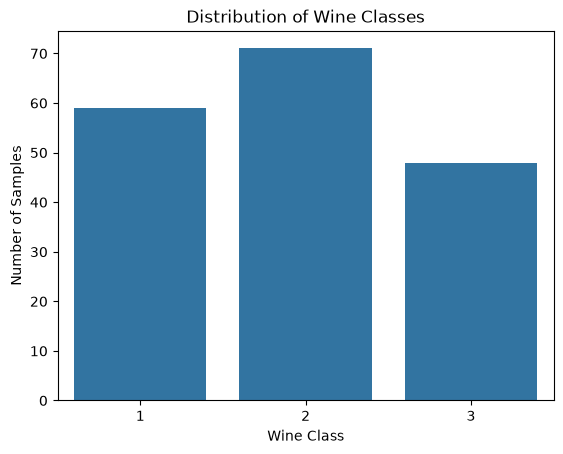

In [7]:
#VISUALIZING CLASS DISTRIBUTION 
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Wine")

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.show()

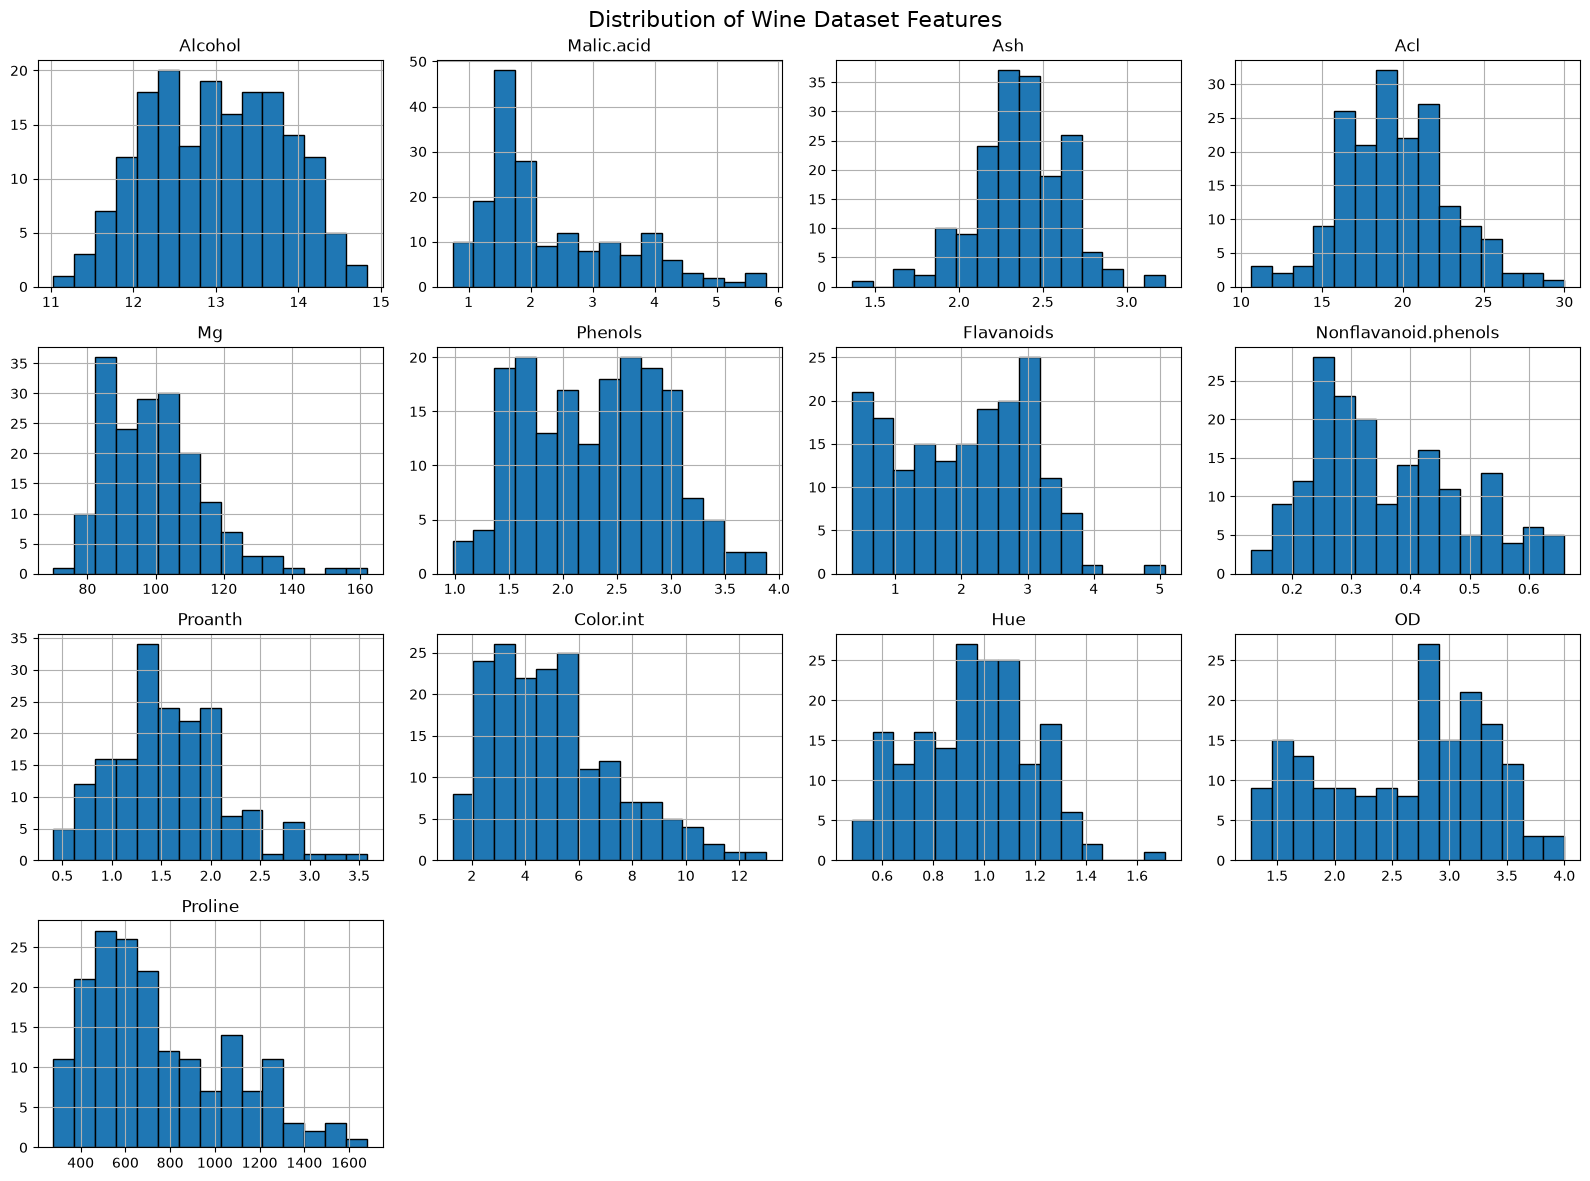

In [8]:
#Check the distribution of numerical features
df.drop(columns="Wine").hist(
    figsize=(16, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Dataset Features", fontsize=16)
plt.tight_layout()
plt.show()

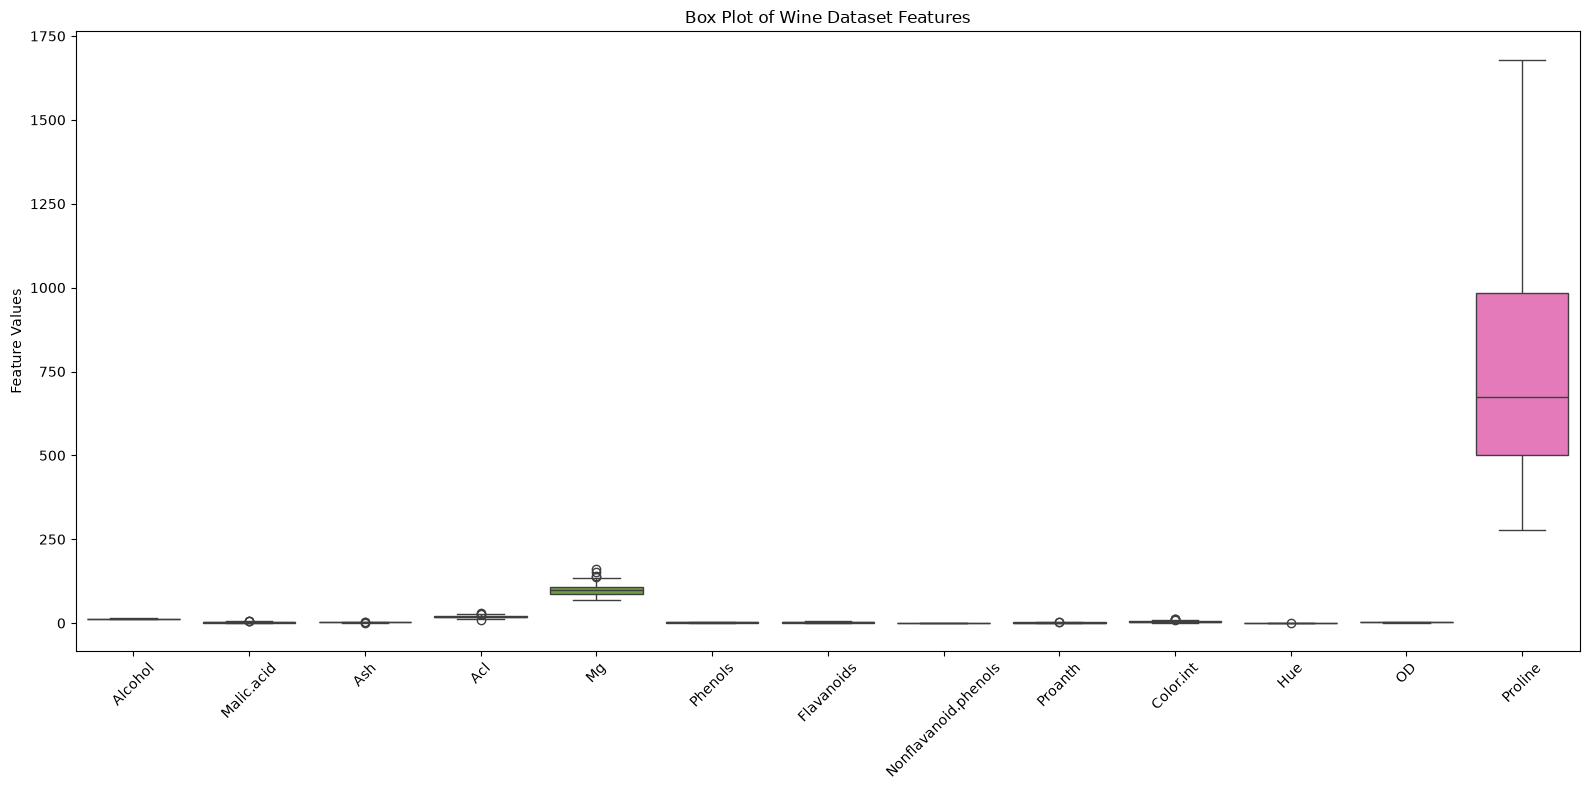

In [9]:
#Detect potential outliers
#A box plot helps us understand the spread of data and identify potential outliers
plt.figure(figsize=(16, 8))
sns.boxplot(data=df.drop(columns="Wine")) #CREATES BOX PLOTS FOR ALL NUMERICAL FEATURES
sns.boxplot(data=df.drop(columns="Wine")) 
plt.title("Box Plot of Wine Dataset Features")
plt.xticks(rotation=45)#rotates feature names to make them easier to read.
plt.ylabel("Feature Values") 
plt.tight_layout() #adjusts spacing so labels don't overlap.
plt.show() #DISPLAYS THE GRAPH

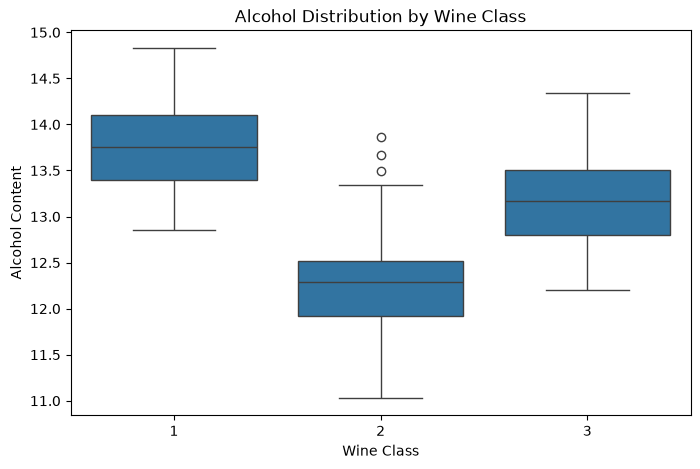

In [10]:
#Step 4: Analyze the relationship between features and wine classes.
#Create a box plot by wine class
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Wine", y="Alcohol")

plt.title("Alcohol Distribution by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol Content")
plt.show()
# to find out Whether the alcohol measurements differ among the three wine classes.
#Which class has a higher or lower median alcohol value.
#How much the alcohol measurements vary within each class.

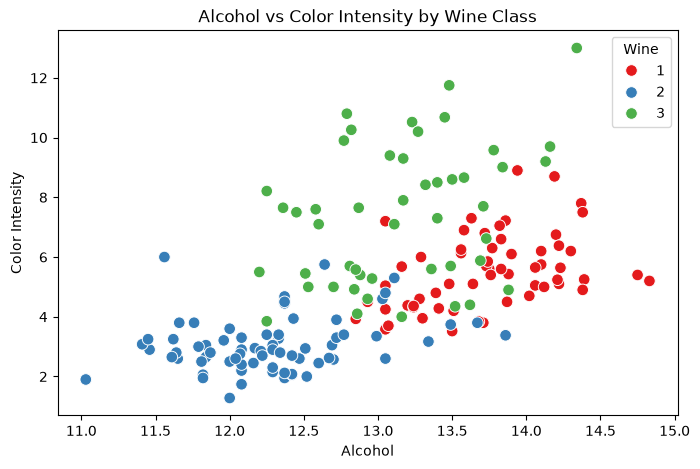

In [11]:
#Compare two features using a scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Alcohol",
    y="Color.int",
    hue="Wine",
    palette="Set1",
    s=70
)
plt.title("Alcohol vs Color Intensity by Wine Class")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.show()

In [12]:
#step 5 corelation analysis 
#Correlation tells us how strongly two numerical features are related.
#- Positive correlation: When one feature increases, the other tends to increase.
#- Negative correlation: When one feature increases, the other tends to decrease.
#- Correlation near zero: There is little or no linear relationship.
#Correlation values range from −1 to +1.
#Calculate the correlation matrix
correlation = df.drop(columns="Wine").corr()
print(correlation)
#this calculates correlations between all 13 numerical features, excluding Wine because it is the target class.

                       Alcohol  Malic.acid       Ash       Acl        Mg  \
Alcohol               1.000000    0.094397  0.211545 -0.310235  0.270798   
Malic.acid            0.094397    1.000000  0.164045  0.288500 -0.054575   
Ash                   0.211545    0.164045  1.000000  0.443367  0.286587   
Acl                  -0.310235    0.288500  0.443367  1.000000 -0.083333   
Mg                    0.270798   -0.054575  0.286587 -0.083333  1.000000   
Phenols               0.289101   -0.335167  0.128980 -0.321113  0.214401   
Flavanoids            0.236815   -0.411007  0.115077 -0.351370  0.195784   
Nonflavanoid.phenols -0.155929    0.292977  0.186230  0.361922 -0.256294   
Proanth               0.136698   -0.220746  0.009652 -0.197327  0.236441   
Color.int             0.546364    0.248985  0.258887  0.018732  0.199950   
Hue                  -0.071747   -0.561296 -0.074667 -0.273955  0.055398   
OD                    0.072343   -0.368710  0.003911 -0.276769  0.066004   
Proline     

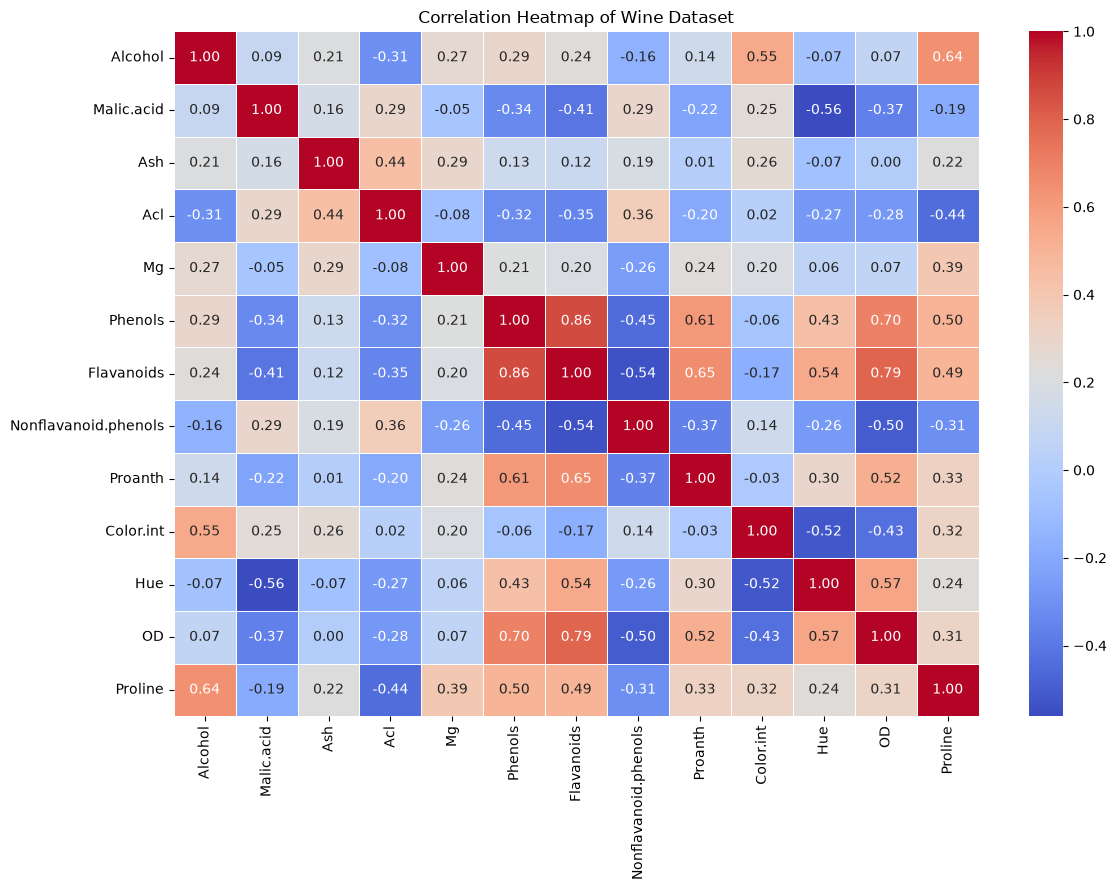

In [13]:
#visualizing corelation using heatmap 
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Dataset")
plt.tight_layout()
plt.show()

Dataset shape: (178, 14)
Number of features: 13
Wine classes: [np.int64(1), np.int64(2), np.int64(3)]

Training samples: 142
Testing samples: 36

Model training completed successfully!

Model Accuracy: 0.9722
Accuracy Percentage: 97.22 %

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       1.00      0.93      0.96        14
           3       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36

Confusion Matrix:
[[12  0  0]
 [ 1 13  0]
 [ 0  0 10]]


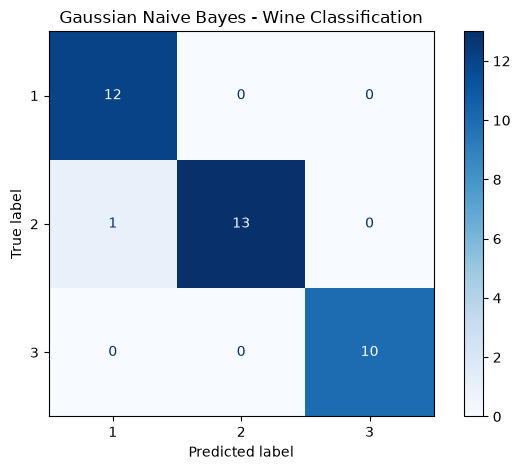

In [3]:
#APPLYING NAIVE BAYES :
# 1. Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 2. Separate features (X) and target (y)
X = df.drop(columns="Wine")
y = df["Wine"]

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Wine classes:", sorted(y.unique()))

# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Create the Gaussian Naive Bayes model
model = GaussianNB()

# 5. Train the model
model.fit(X_train, y_train)

print("\nModel training completed successfully!")

# 6. Make predictions on test data
y_pred = model.predict(X_test)

# 7. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

# 8. Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:") # CONFUSION MATRIX : It compares the actual classes with the classes predicted by the model.
print(cm)

# 10. Visualize confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Gaussian Naive Bayes - Wine Classification")
plt.tight_layout()
plt.show()
